In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Process Improvement Recommendations")
print("Libraries imported successfully!")

Process Improvement Recommendations
Libraries imported successfully!


In [3]:
import pandas as pd

bottlenecks = pd.read_csv("careflow_bottleneck_candidates.csv")

print("Bottleneck data loaded successfully!")
print("Dataset shape:", bottlenecks.shape)

display(bottlenecks.head(10))

Bottleneck data loaded successfully!
Dataset shape: (17, 5)


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
0,Lab,Appointment,125,192.800000,158.0
1,Lab,Prescription,369,107.002710,33.0
2,Lab,Imaging,409,106.122249,52.0
3,Appointment,Imaging,1599,70.612883,46.0
4,Appointment,Lab,354,59.135593,29.5
5,Imaging,Appointment,288,55.135417,18.0
6,Prescription,Imaging,2850,53.849825,34.0
7,Imaging,Lab,614,44.894137,29.0
8,Appointment,Prescription,47630,43.196893,25.0
9,Imaging,Prescription,1662,35.589651,25.0


In [4]:
print("Column names:")
print(bottlenecks.columns.tolist())

print("\nData types:")
print(bottlenecks.dtypes)

print("\nMissing values:")
print(bottlenecks.isnull().sum())

Column names:
['Activity_Name', 'Next_Activity', 'Transition_Count', 'Average_Waiting_Time_Minutes', 'Median_Waiting_Time_Minutes']

Data types:
Activity_Name                       str
Next_Activity                       str
Transition_Count                  int64
Average_Waiting_Time_Minutes    float64
Median_Waiting_Time_Minutes     float64
dtype: object

Missing values:
Activity_Name                   0
Next_Activity                   0
Transition_Count                0
Average_Waiting_Time_Minutes    0
Median_Waiting_Time_Minutes     0
dtype: int64


In [5]:
top_candidates = bottlenecks.sort_values(
    by="Average_Waiting_Time_Minutes",
    ascending=False
)

display(top_candidates.head(10))

,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
0,Lab,Appointment,125,192.800000,158.0
1,Lab,Prescription,369,107.002710,33.0
2,Lab,Imaging,409,106.122249,52.0
3,Appointment,Imaging,1599,70.612883,46.0
4,Appointment,Lab,354,59.135593,29.5
5,Imaging,Appointment,288,55.135417,18.0
6,Prescription,Imaging,2850,53.849825,34.0
7,Imaging,Lab,614,44.894137,29.0
8,Appointment,Prescription,47630,43.196893,25.0
9,Imaging,Prescription,1662,35.589651,25.0


In [6]:
print(top_candidates.head(10).to_string(index=False))

Activity_Name Next_Activity  Transition_Count  Average_Waiting_Time_Minutes  Median_Waiting_Time_Minutes
          Lab   Appointment               125                    192.800000                        158.0
          Lab  Prescription               369                    107.002710                         33.0
          Lab       Imaging               409                    106.122249                         52.0
  Appointment       Imaging              1599                     70.612883                         46.0
  Appointment           Lab               354                     59.135593                         29.5
      Imaging   Appointment               288                     55.135417                         18.0
 Prescription       Imaging              2850                     53.849825                         34.0
      Imaging           Lab               614                     44.894137                         29.0
  Appointment  Prescription             47630          

In [7]:
recommendations = {
    "Lab → Appointment": "Review appointment scheduling and lab result follow-up workflows.",
    "Lab → Prescription": "Review how lab results are communicated to prescribing doctors.",
    "Lab → Imaging": "Review coordination between laboratory and imaging services.",
    "Appointment → Imaging": "Review imaging referral and scheduling coordination.",
    "Appointment → Lab": "Review laboratory test ordering and scheduling.",
    "Imaging → Appointment": "Review imaging result availability before follow-up appointments.",
    "Prescription → Imaging": "Review coordination between prescriptions and imaging requests.",
    "Imaging → Lab": "Review coordination of imaging and laboratory investigations.",
    "Appointment → Prescription": "Review prescription workflow and doctor handoff.",
    "Imaging → Prescription": "Review how imaging findings are communicated to prescribing doctors.",
    "Prescription → Lab": "Review prescription and laboratory order coordination.",
    "Imaging → Imaging": "Review repeated imaging activity and check whether it is clinically appropriate.",
    "Prescription → Pharmacy": "Review prescription-to-pharmacy communication.",
    "Prescription → Prescription": "Review repeated prescription records and determine whether they represent valid updates.",
    "Pharmacy → Pharmacy": "Review repeated pharmacy transactions.",
    "Lab → Lab": "Review repeated laboratory records and determine whether they represent valid tests.",
    "Appointment → Appointment": "Review repeated appointment records and distinguish updates from duplicate entries."
}

print("Recommendation dictionary created.")
print("Number of transition patterns:", len(recommendations))

Recommendation dictionary created.
Number of transition patterns: 17


In [8]:
print("Available bottleneck columns:")
print(bottlenecks.columns.tolist())

print("\nSample bottleneck records:")
display(bottlenecks.head(5))

Available bottleneck columns:
['Activity_Name', 'Next_Activity', 'Transition_Count', 'Average_Waiting_Time_Minutes', 'Median_Waiting_Time_Minutes']

Sample bottleneck records:


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes
0,Lab,Appointment,125,192.800000,158.0
1,Lab,Prescription,369,107.002710,33.0
2,Lab,Imaging,409,106.122249,52.0
3,Appointment,Imaging,1599,70.612883,46.0
4,Appointment,Lab,354,59.135593,29.5


In [9]:
print(bottlenecks.columns.tolist())

['Activity_Name', 'Next_Activity', 'Transition_Count', 'Average_Waiting_Time_Minutes', 'Median_Waiting_Time_Minutes']


In [10]:
print("Detected columns:")
for col in bottlenecks.columns:
    print("-", col)

print("\nFirst record:")
print(bottlenecks.iloc[0].to_dict())


Detected columns:
- Activity_Name
- Next_Activity
- Transition_Count
- Average_Waiting_Time_Minutes
- Median_Waiting_Time_Minutes

First record:
{'Activity_Name': 'Lab', 'Next_Activity': 'Appointment', 'Transition_Count': 125, 'Average_Waiting_Time_Minutes': 192.8, 'Median_Waiting_Time_Minutes': 158.0}


In [11]:
# Automatically identify transition column
transition_col = next(
    (c for c in bottlenecks.columns
     if "transition" in c.lower()),
    None
)

if transition_col is None:
    raise ValueError("Transition column not found. Please share bottlenecks.columns.tolist().")

# Add recommendations
bottlenecks["Improvement_Recommendation"] = (
    bottlenecks[transition_col]
    .astype(str)
    .map(recommendations)
    .fillna("Review this transition and investigate its workflow.")
)

# Save recommendations
bottlenecks.to_csv(
    "careflow_process_improvement_recommendations.csv",
    index=False
)

print("Recommendations CSV saved successfully!")
display(bottlenecks.head(10))

Recommendations CSV saved successfully!


,Activity_Name,Next_Activity,Transition_Count,Average_Waiting_Time_Minutes,Median_Waiting_Time_Minutes,Improvement_Recommendation
0,Lab,Appointment,125,192.800000,158.0,Review this transition and investigate its wor...
1,Lab,Prescription,369,107.002710,33.0,Review this transition and investigate its wor...
2,Lab,Imaging,409,106.122249,52.0,Review this transition and investigate its wor...
3,Appointment,Imaging,1599,70.612883,46.0,Review this transition and investigate its wor...
4,Appointment,Lab,354,59.135593,29.5,Review this transition and investigate its wor...
5,Imaging,Appointment,288,55.135417,18.0,Review this transition and investigate its wor...
6,Prescription,Imaging,2850,53.849825,34.0,Review this transition and investigate its wor...
7,Imaging,Lab,614,44.894137,29.0,Review this transition and investigate its wor...
8,Appointment,Prescription,47630,43.196893,25.0,Review this transition and investigate its wor...
9,Imaging,Prescription,1662,35.589651,25.0,Review this transition and investigate its wor...


In [12]:
# Identify the required columns automatically
transition_col = next(
    (c for c in bottlenecks.columns if "transition" in c.lower()),
    None
)

avg_col = next(
    (c for c in bottlenecks.columns
     if "average" in c.lower() and ("wait" in c.lower() or "time" in c.lower())),
    None
)

count_col = next(
    (c for c in bottlenecks.columns
     if "count" in c.lower() or "frequency" in c.lower()),
    None
)

if not all([transition_col, avg_col, count_col]):
    raise ValueError(
        "Required columns not detected. Please share: "
        + str(bottlenecks.columns.tolist())
    )

# Create priority scores
priority = bottlenecks[
    [transition_col, avg_col, count_col]
].copy()

priority.columns = [
    "Transition",
    "Average_Waiting_Time_Minutes",
    "Transition_Count"
]

priority["Waiting_Time_Score"] = (
    priority["Average_Waiting_Time_Minutes"].rank(pct=True) * 100
)

priority["Frequency_Score"] = (
    priority["Transition_Count"].rank(pct=True) * 100
)

priority["Priority_Score"] = (
    priority["Waiting_Time_Score"] * 0.5
    + priority["Frequency_Score"] * 0.5
)

priority["Priority_Level"] = pd.cut(
    priority["Priority_Score"],
    bins=[-1, 33.33, 66.67, 100],
    labels=["Low", "Medium", "High"]
)

priority = priority.sort_values(
    "Priority_Score",
    ascending=False
)

priority.to_csv(
    "careflow_improvement_priority_matrix.csv",
    index=False
)

print("Improvement priority matrix saved successfully!")
display(priority)

Improvement priority matrix saved successfully!


,Transition,Average_Waiting_Time_Minutes,Transition_Count,Waiting_Time_Score,Frequency_Score,Priority_Score,Priority_Level
8,47630,43.196893,47630,52.941176,100.000000,76.470588,High
3,1599,70.612883,1599,82.352941,58.823529,70.588235,High
6,2850,53.849825,2850,64.705882,70.588235,67.647059,High
2,409,106.122249,409,88.235294,47.058824,67.647059,High
1,369,107.002710,369,94.117647,41.176471,67.647059,High
10,5295,34.137677,5295,41.176471,76.470588,58.823529,Medium
7,614,44.894137,614,58.823529,52.941176,55.882353,Medium
0,125,192.800000,125,100.000000,11.764706,55.882353,Medium
4,354,59.135593,354,76.470588,35.294118,55.882353,Medium
13,12362,2.923718,12362,23.529412,88.235294,55.882353,Medium


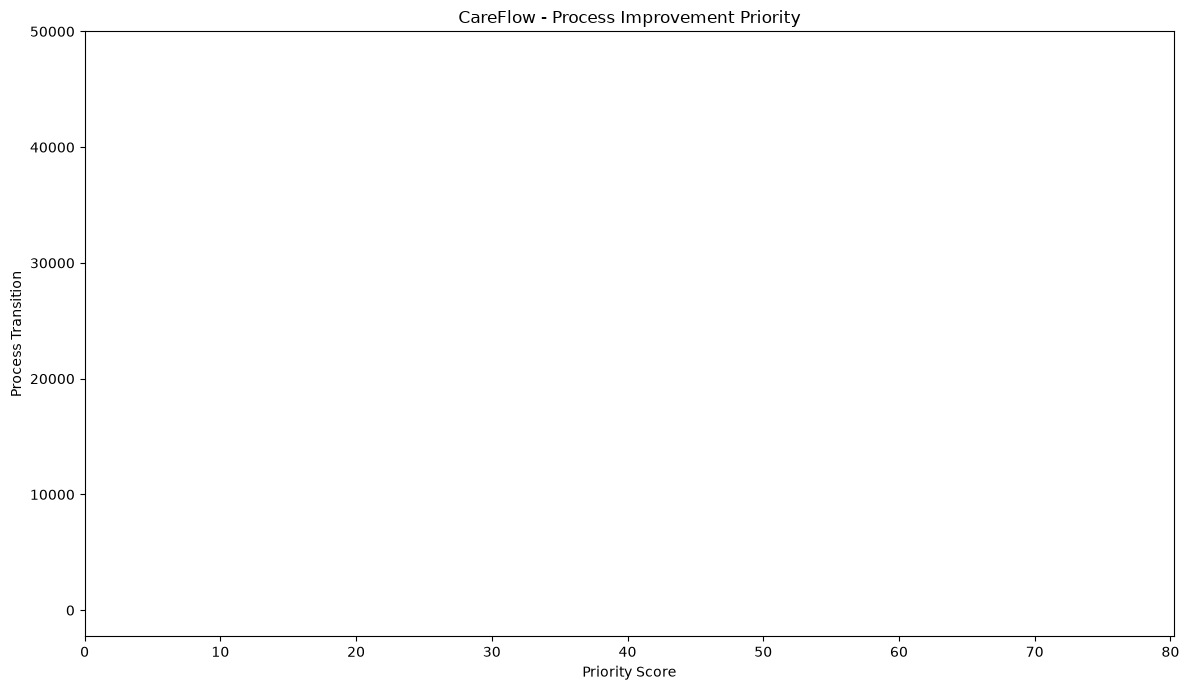

Priority chart saved successfully!


In [13]:
plt.figure(figsize=(12, 7))

chart_data = priority.sort_values(
    "Priority_Score",
    ascending=True
)

plt.barh(
    chart_data["Transition"],
    chart_data["Priority_Score"]
)

plt.xlabel("Priority Score")
plt.ylabel("Process Transition")
plt.title("CareFlow - Process Improvement Priority")

plt.tight_layout()

plt.savefig(
    "careflow_improvement_priority_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Priority chart saved successfully!")

In [14]:
import os

day13_files = [
    "careflow_process_improvement_recommendations.csv",
    "careflow_improvement_priority_matrix.csv",
    "careflow_improvement_priority_chart.png"
]

print("Day 13 file verification:\n")

for file in day13_files:
    if os.path.exists(file):
        print("✓ Found:", file)
    else:
        print("✗ Missing:", file)

Day 13 file verification:

✓ Found: careflow_process_improvement_recommendations.csv
✓ Found: careflow_improvement_priority_matrix.csv
✓ Found: careflow_improvement_priority_chart.png


In [15]:
import os

files = [
    "13_process_improvement_recommendations.ipynb",
    "careflow_process_improvement_recommendations.csv",
    "careflow_improvement_priority_matrix.csv",
    "careflow_improvement_priority_chart.png"
]

for file in files:
    print(("FOUND: " if os.path.exists(file) else "MISSING: ") + file)

MISSING: 13_process_improvement_recommendations.ipynb
FOUND: careflow_process_improvement_recommendations.csv
FOUND: careflow_improvement_priority_matrix.csv
FOUND: careflow_improvement_priority_chart.png
